# Session 12: Building and Training CNN Models with PyTorch

**Learning goals:**

- Describe the main stages of a CNN classifier.
- Build a simple CNN using PyTorch layers and a custom `forward()` method.
- Explain and implement the PyTorch training loop.
- Evaluate a trained classifier using accuracy and macro F1 on held-out images.
- Freeze a pretrained CNN, replace its classification head and train the new head.

**Prerequisites:**

- Sessions 9–11, basic Python classes and classification concepts.
- Python with PyTorch, torchvision, pandas, NumPy, Matplotlib and scikit-learn installed.
- Run this notebook from the course folder, using `sample_data/digit_images/` from the supplied digit image bundle.
- Internet access for the first download of pretrained ResNet18 weights.
- A GPU is optional; all examples can run on CPU, although transfer learning is slower.

## Outline

1. Building a CNN Feature Block with Conv2d and MaxPool2d
2. Build a Simple CNN with PyTorch
3. Train a CNN with PyTorch
4. Evaluate the Model
5. Transfer Learning with a Pretrained CNN

## 1. Building a CNN Feature Block with Conv2d and MaxPool2d

Work through [Session 12.1: Building a CNN Feature Block with Conv2d and MaxPool2d](<Session12.1 CNN Feature Blocks and Training Data Preparation.ipynb>) to explore convolution, activation and pooling, then return here to train the same model.

The model uses **Conv2d → ReLU → MaxPool2d → Flatten → Linear**. One 28 × 28 greyscale image becomes 16 feature maps of 14 × 14. Flatten joins these into 3,136 values, and Linear produces ten raw class scores (logits).

| Stage | PyTorch layer | Output shape for a batch of N images |
|---|---|---|
| Input | Image tensor | `[N, 1, 28, 28]` |
| Feature extraction | `nn.Conv2d(1, 16, 3, stride=1, padding=1)` | `[N, 16, 28, 28]` |
| Activation | `nn.ReLU()` | `[N, 16, 28, 28]` |
| Spatial reduction | `nn.MaxPool2d(2, stride=2)` | `[N, 16, 14, 14]` |
| Flatten | `nn.Flatten(start_dim=1)` | `[N, 3136]` |
| Classification | `nn.Linear(3136, 10)` | `[N, 10]` |

The final layer returns logits directly. `nn.CrossEntropyLoss` includes the required log-softmax calculation. Softmax is useful for displaying probabilities and preserves the class selected by `argmax`.

## 2. Build a Simple CNN with PyTorch

This example uses the same `DigitCNN` class and `model` variable as Session 12.1 and its practice notebook.

### 2.1 PyTorch classes, functions and methods

`torch` provides tensor operations, while `torch.nn` provides trainable layers and loss functions. Most `nn` layers are classes: calling a class creates a layer object, and calling that object applies its operation to a tensor.

| API | Role in this model | Key arguments or behaviour |
|---|---|---|
| `nn.Module` | Base class for the complete model | Registers layers assigned as attributes |
| `super().__init__()` | Initialises the base module | Call before assigning layers |
| `nn.Sequential(...)` | Groups layers into an ordered pipeline | Passes each layer's output to the next |
| `nn.Conv2d(...)` | Creates a trainable convolution layer | `in_channels`, `out_channels`, `kernel_size`, `padding` |
| `nn.ReLU()` | Applies the activation operation | Replaces negative values with zero |
| `nn.MaxPool2d(...)` | Reduces spatial size | `kernel_size=2` uses a 2 × 2 pooling window |
| `nn.Flatten(...)` | Makes one feature vector per image | `start_dim=1` preserves the batch dimension |
| `nn.Linear(...)` | Creates a fully connected layer | `in_features` and `out_features` specify its input and output sizes |
| `forward(self, images)` | Defines the model's computation | Connects the feature extractor to the classifier |
| `model(images)` | Runs the model on a batch | Invokes the module's forward machinery; prefer this to calling `forward()` directly |

[PyTorch neural-network modules](https://docs.pytorch.org/docs/stable/nn.html)

In [1]:
import torch
from torch import nn

class DigitCNN(nn.Module):
    """Extract image features and produce ten digit-class scores."""

    def __init__(self):
        super().__init__()  # Initialise the parent module before adding layers.
        self.features = nn.Sequential(
            nn.Conv2d(
                in_channels=1,  # Accept one greyscale channel.
                out_channels=16,  # Produce 16 feature maps.
                kernel_size=3,  # Apply a 3 × 3 filter.
                stride=1,  # Move one pixel at each step.
                padding=1,  # Keep the 28 × 28 spatial size.
            ),
            nn.ReLU(),  # Replace negative responses with zero.
            nn.MaxPool2d(kernel_size=2, stride=2),  # Reduce each map to 14 × 14.
        )
        self.classifier = nn.Sequential(
            nn.Flatten(start_dim=1),  # Flatten the maps while keeping the batch axis.
            nn.Linear(in_features=16 * 14 * 14, out_features=10),  # Produce ten class scores directly from the flattened features.
        )

    def forward(self, images):
        features = self.features(images)  # Extract and pool local image features.
        return self.classifier(features)  # Convert the features into ten class scores.

torch.manual_seed(42)  # Reproduce the initial random model weights.
model = DigitCNN()  # Create the same feature block and classifier as the lesson.
print(model)
print('Parameters:', sum(parameter.numel() for parameter in model.parameters()))
print('Weights are randomly initialised; this model has not been trained.')


DigitCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=10, bias=True)
  )
)
Parameters: 31530
Weights are randomly initialised; this model has not been trained.


### 2.2 Check the model before training

A temporary batch checks that the layers connect correctly. It does not train the model. Two input images should produce a tensor with shape `[2, 10]`.

`model.parameters()` provides the tensors that an optimiser can update. `numel()` counts the values in each parameter tensor.

In [2]:
CHECK_BATCH_SIZE = 2
IMAGE_SIZE = 28
NUM_CLASSES = 10
example_images = torch.zeros(CHECK_BATCH_SIZE, 1, IMAGE_SIZE, IMAGE_SIZE)
example_logits = model(example_images)  # Run the forward pass through all layers.
parameter_count = sum(parameter.numel() for parameter in model.parameters())
assert example_logits.shape == (CHECK_BATCH_SIZE, NUM_CLASSES)
print('Output shape:', tuple(example_logits.shape))
print('Trainable parameters:', parameter_count)

Output shape: (2, 10)
Trainable parameters: 31530


## 3. Train a CNN with PyTorch

### 3.1 Training workflow

An **epoch** is one pass through the training examples. The diagram summarises the main training steps: clear previous gradients, run a forward pass, calculate the loss, run a backward pass and update the weights. Repeat these steps over the training examples for each epoch, then finish after the final epoch.

![Training workflow showing the main steps: start an epoch, clear gradients, run a forward pass, calculate loss, run a backward pass and update weights; repeat for more epochs, then finish training after the final epoch.](assets/session12/training-workflow.svg)

### 3.2 Loading Images for Training and Testing

[Download the digit image bundle](assets/digit_images.zip){download="digit_images.zip"} and extract it into the working folder.

Use ImageFolder and transforms as in Session 13.2. Normalise images to −1–1 to match the Session 12.1 practice inputs.
Split 80% for training and 20% for testing. Each DataLoader contains its entire subset in one batch.

To train in [the practice notebook](<Session12.1 CNN Practice.ipynb>), run its existing cells first. Then copy the code cells from **3.2, 3.3 and 3.4**, in that order, into new cells in Section 4, before the model-saving step in Section 5. Section 3.2 supplies its own imports and constants, Section 3.3 uses the existing `model`, and Section 3.4 trains it for one epoch and prints loss and accuracy. Keep `sample_data/digit_images/` available in the working directory.

In [3]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import random_split, DataLoader

RANDOM_SEED = 42
DIGIT_ROOT = "sample_data/digit_images"
IMAGE_SIZE = (28, 28)
NORMALISATION_MEAN = 0.5
NORMALISATION_STD = 0.5
torch.manual_seed(RANDOM_SEED)  # Reproduce the random split and training operations.

digit_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),  # Keep one intensity channel.
    transforms.Resize(IMAGE_SIZE),  # Set the height and width to 28 pixels.
    transforms.ToTensor(),  # Convert pixels to a float tensor in [0, 1].
    transforms.Normalize(mean=(NORMALISATION_MEAN,), std=(NORMALISATION_STD,)),  # Match the practice input range [-1, 1].
])
full_dataset = datasets.ImageFolder(DIGIT_ROOT, transform=digit_transform)  # Read labels from class folders.
NUM_CLASSES = len(full_dataset.classes)
train_size = int(0.8 * len(full_dataset))  # Use 80% of the images for training.
test_size = len(full_dataset) - train_size
train_dataset, test_dataset = random_split(full_dataset, [train_size, test_size])  # Keep the two subsets separate.
train_loader = DataLoader(
    train_dataset, batch_size=len(train_dataset), shuffle=True,  # Put all training images in one shuffled batch.
)
test_loader = DataLoader(
    test_dataset, batch_size=len(test_dataset), shuffle=False,  # Put all test images in one fixed-order batch.
)
print("Classes:", full_dataset.classes)
print("Training images:", len(train_dataset), "Batches:", len(train_loader))
print("Test images:", len(test_dataset), "Batches:", len(test_loader))

Classes: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']
Training images: 192 Batches: 1
Test images: 48 Batches: 1


### 3.3 Loss function, optimiser and device

`nn.CrossEntropyLoss()` compares a batch of logits with integer class labels. It includes the required log-softmax calculation, so do not add softmax to the model before this loss.

`torch.optim.Adam(model.parameters(), lr=...)` creates an optimiser for the supplied parameters. The learning rate controls the scale of its updates. `model.to(device)` moves the model to the chosen device; each batch must be moved to the same device.

[Cross-entropy loss](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html) · [Adam optimiser](https://docs.pytorch.org/docs/stable/generated/torch.optim.Adam.html)

In [4]:
from torch import nn

if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')

LEARNING_RATE = 0.001
model = model.to(device)  # Move parameters before constructing the optimiser.
criterion = nn.CrossEntropyLoss()  # Expect logits and class indices, rather than probabilities.
simple_optimiser = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
print('Training device:', device)

Training device: mps


### 3.4 The five operations in a training step

| Operation | Purpose |
|---|---|
| `optimiser.zero_grad()` | Clears gradients from the previous epoch |
| `logits = model(images)` | Computes class scores with the current weights |
| `loss = criterion(logits, labels)` | Measures prediction error |
| `loss.backward()` | Computes gradients for trainable parameters |
| `optimiser.step()` | Updates parameters using those gradients |

`model.train()` activates training behaviour in layers such as Dropout and BatchNorm. It does not run the training loop itself.

The helper processes the loader's only batch using `next(iter(loader))`. There is no loop over batches.
It completes one training epoch and prints loss and accuracy. Section 3.5 repeats this step across epochs.

In [5]:
def train_one_epoch(model, loader, optimiser, loss_function, device):
    model.train()  # Activate training behaviour.

    images, labels = next(iter(loader))  # Retrieve the only batch, containing all training images.
    images, labels = images.to(device), labels.to(device)
    optimiser.zero_grad()  # Clear gradients from the previous epoch.
    logits = model(images)  # Compute scores for the complete training set.
    loss = loss_function(logits, labels)  # Calculate the mean classification loss.
    loss.backward()  # Calculate parameter gradients.
    optimiser.step()  # Update weights once per epoch.
    accuracy = (logits.argmax(dim=1) == labels).float().mean().item()
    return loss.item(), accuracy

import time

initial_epoch_start = time.perf_counter()  # Time the first training epoch.
train_loss, train_accuracy = train_one_epoch(
    model, train_loader, simple_optimiser, criterion, device,
)
initial_epoch_seconds = time.perf_counter() - initial_epoch_start
print(f"One training epoch: loss={train_loss:.3f}, accuracy={train_accuracy:.3f}")

One training epoch: loss=2.367, accuracy=0.094


### 3.5 Train across epochs

Continue from the first epoch for 30 more epochs. Each epoch uses the single training batch
and updates the weights once. Record training loss and accuracy, then evaluate the final
model on the test set in Section 4.

In [6]:
import pandas as pd

def fit(model, train_loader, optimiser, loss_function, device, epochs):
    history = []
    start_time = time.perf_counter()  # Measure elapsed training time.
    for epoch in range(1, epochs + 1):
        train_loss, train_accuracy = train_one_epoch(
            model, train_loader, optimiser, loss_function, device,
        )
        history.append({"epoch": epoch, "train_loss": train_loss, "train_accuracy": train_accuracy})
        print(f"Epoch {epoch}/{epochs}: loss={train_loss:.3f}, accuracy={train_accuracy:.3f}")
    return pd.DataFrame(history), time.perf_counter() - start_time

SIMPLE_EPOCHS = 30
simple_history, simple_seconds = fit(
    model, train_loader, simple_optimiser, criterion, device, epochs=SIMPLE_EPOCHS,
)
simple_seconds += initial_epoch_seconds  # Include the first epoch in the comparison time.

Epoch 1/30: loss=2.320, accuracy=0.260
Epoch 2/30: loss=2.201, accuracy=0.115
Epoch 3/30: loss=2.019, accuracy=0.292
Epoch 4/30: loss=1.897, accuracy=0.344
Epoch 5/30: loss=1.803, accuracy=0.635
Epoch 6/30: loss=1.726, accuracy=0.630
Epoch 7/30: loss=1.626, accuracy=0.615
Epoch 8/30: loss=1.514, accuracy=0.729
Epoch 9/30: loss=1.415, accuracy=0.766
Epoch 10/30: loss=1.333, accuracy=0.797
Epoch 11/30: loss=1.264, accuracy=0.740
Epoch 12/30: loss=1.196, accuracy=0.734
Epoch 13/30: loss=1.123, accuracy=0.781
Epoch 14/30: loss=1.053, accuracy=0.812
Epoch 15/30: loss=0.988, accuracy=0.859
Epoch 16/30: loss=0.932, accuracy=0.859
Epoch 17/30: loss=0.886, accuracy=0.870
Epoch 18/30: loss=0.842, accuracy=0.865
Epoch 19/30: loss=0.792, accuracy=0.880
Epoch 20/30: loss=0.741, accuracy=0.896
Epoch 21/30: loss=0.701, accuracy=0.906
Epoch 22/30: loss=0.670, accuracy=0.875
Epoch 23/30: loss=0.640, accuracy=0.870
Epoch 24/30: loss=0.606, accuracy=0.885
Epoch 25/30: loss=0.572, accuracy=0.906
Epoch 26/

## 4. Evaluate the Model

Evaluate the held-out test images. Accuracy measures the proportion of correct predictions.
Macro F1 combines precision and recall, giving each digit class equal weight.


Use `model.eval()` and `torch.no_grad()` to predict without updating weights.

In [7]:
from sklearn.metrics import accuracy_score, f1_score

test_images, test_labels = next(iter(test_loader))  # Retrieve the complete test set in one batch.
model.eval()  # Select evaluation behaviour.
with torch.no_grad():  # Predict without recording gradients or updating weights.
    test_logits = model(test_images.to(device))
    test_loss = criterion(test_logits, test_labels.to(device)).item()
    predicted_labels = test_logits.argmax(dim=1).cpu()  # Select one class per image and return labels to the CPU.

test_accuracy = accuracy_score(test_labels, predicted_labels)
test_f1 = f1_score(
    test_labels, predicted_labels,
    labels=list(range(NUM_CLASSES)), average="macro", zero_division=0,  # Give each digit class equal weight.
)
print(f"Test accuracy: {test_accuracy:.3f}")
print(f"Macro F1 score: {test_f1:.3f}")

Test accuracy: 0.771
Macro F1 score: 0.763


Compare the true and predicted labels for five test images.


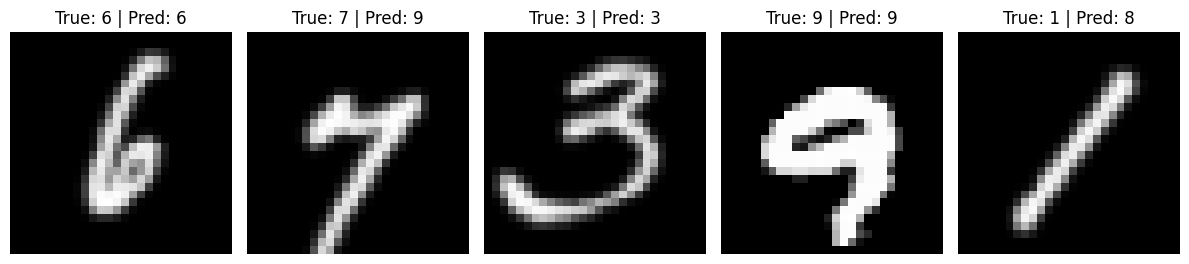

In [8]:
import matplotlib.pyplot as plt

DISPLAY_COUNT = 5
figure, axes = plt.subplots(1, DISPLAY_COUNT, figsize=(12, 3))
for position, axis in enumerate(axes):
    axis.imshow(test_images[position].squeeze(0), cmap="gray", vmin=-1, vmax=1)  # Display the normalised image pixels.
    actual = int(test_labels[position].item())
    predicted = int(predicted_labels[position].item())
    axis.set_title(f"True: {actual} | Pred: {predicted}")
    axis.axis("off")
plt.tight_layout()
plt.show()

## 5. Transfer Learning with a Pretrained CNN

### 5.1 Reuse learned features

Transfer learning starts with weights learned on another task. We use **ResNet18 pretrained on ImageNet**, replace its classification head with a ten-class digit classifier, and train it on the same MNIST samples used above.

Freeze the pretrained backbone and train only the new classification head. The backbone keeps its learned features while the new head learns to map those features to ten digit classes. This is transfer learning with a frozen feature extractor; fine-tuning would also update some pretrained weights.

The diagram shows the model settings and training settings used in Sections 5.2–5.4. Freezing parameters controls which weights can learn, while `eval()` and `train()` control layer behaviour.

![Transfer-learning workflow: load pretrained ResNet18, freeze existing parameters, replace the classification head, prepare inputs, set model modes, select trainable optimiser parameters, and train the new head.](assets/session12/transfer-learning-workflow.svg)

ImageNet contains natural colour photographs, whereas MNIST contains handwritten digits. This difference between source and target tasks means transfer learning is not guaranteed to outperform our small CNN. The models also differ in size, training duration and input representation, so the final table is a classroom comparison rather than a controlled architecture benchmark.

[PyTorch transfer-learning tutorial](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html) · [ResNet18 model and pretrained weights](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html)

### 5.2 Load the pretrained model and replace its head

| API | Purpose |
|---|---|
| `ResNet18_Weights.DEFAULT` | Selects the recommended pretrained weight set |
| `resnet18(weights=...)` | Constructs the model and loads those weights |
| `parameter.requires_grad = False` | Stops gradient calculation for that parameter |
| `model.fc.in_features` | Reports the feature-vector size entering the original head |
| `model.fc = nn.Linear(...)` | Replaces the original head with a new trainable layer |
| `filter(...)` | Supplies only trainable parameters to the optimiser |

Replacing the head after freezing the existing parameters leaves the new head trainable. The first call downloads weights; later calls reuse the saved copy.

In [9]:
import os
from torchvision.models import resnet18, ResNet18_Weights

WEIGHT_CACHE = '../archive/AI_SS/session12/torch-cache'
os.makedirs(WEIGHT_CACHE, exist_ok=True)
torch.hub.set_dir(WEIGHT_CACHE)  # Keep downloaded weights in the workspace cache.
torch.manual_seed(RANDOM_SEED)
pretrained_weights = ResNet18_Weights.DEFAULT
transfer_model = resnet18(weights=pretrained_weights)  # Load ImageNet feature-extractor weights.
for parameter in transfer_model.parameters():
    parameter.requires_grad = False  # Freeze all existing parameters.
head_input_features = transfer_model.fc.in_features
transfer_model.fc = nn.Linear(head_input_features, NUM_CLASSES)  # New head starts trainable.
transfer_model = transfer_model.to(device)
print('New classification head:', transfer_model.fc)
print('Trainable parameters:', sum(p.numel() for p in transfer_model.parameters() if p.requires_grad))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to ../archive/AI_SS/session12/torch-cache/checkpoints/resnet18-f37072fd.pth


100.0%


New classification head: Linear(in_features=512, out_features=10, bias=True)
Trainable parameters: 5130


### 5.3 Ready-to-run input code

Retrieve the single training batch and prepare its inputs for ResNet18 before training.

In [10]:
pretrained_transform = pretrained_weights.transforms()

def resnet_input(images):
    # Undo the classroom normalisation before applying the pretrained transform.
    images_01 = images * NORMALISATION_STD + NORMALISATION_MEAN
    images_rgb = images_01.repeat(1, 3, 1, 1)  # Supply three colour channels.
    return pretrained_transform(images_rgb)

transfer_train_loader = DataLoader(
    train_dataset, batch_size=len(train_dataset), shuffle=True,  # Supply one complete training batch.
)

transfer_images, transfer_labels = next(iter(transfer_train_loader))  # Retrieve all training images and labels.
transfer_images = resnet_input(transfer_images).to(device)  # Match the pretrained model's input format.
transfer_labels = transfer_labels.to(device)

### 5.4 Train the new classification head

Freezing parameters and choosing the model's mode are separate actions. BatchNorm running statistics can change in training mode even when its parameters are frozen. Keep the frozen backbone in evaluation mode and place only the new head in training mode.

The training loop still computes loss and calls `backward()` and `step()`, but the optimiser updates only the new head.

In [ ]:
HEAD_LEARNING_RATE = 0.001  # Set the step size for head updates.
HEAD_EPOCHS = 2  # Make two passes through the training examples.
head_optimiser = torch.optim.Adam(
    filter(lambda parameter: parameter.requires_grad, transfer_model.parameters()),  # Optimise only trainable parameters.
    lr=HEAD_LEARNING_RATE,  # Set the learning rate for the new head.
)
transfer_model.eval()  # Keep the frozen backbone's BatchNorm statistics fixed.
transfer_model.fc.train()  # Select training behaviour for the new head.
head_start = time.perf_counter()
for epoch in range(HEAD_EPOCHS):
    head_optimiser.zero_grad()  # Clear gradients from the previous epoch.
    logits = transfer_model(transfer_images)  # Process the single training batch.
    loss = criterion(logits, transfer_labels)
    loss.backward()  # Calculate gradients for the trainable head.
    head_optimiser.step()  # Update the head's parameters.
    print(f"Head epoch {epoch + 1}/{HEAD_EPOCHS}: loss={loss.item():.3f}")
head_seconds = time.perf_counter() - head_start


### 5.5 Compare the trained models

Evaluate the ResNet18 model with its trained classification head on the same test images used for the simple CNN. Keep the backbone frozen during evaluation.

Training time covers training the new head. It excludes the weight download, input preparation, final testing and model construction. CUDA and MPS operations may be asynchronous, so these elapsed times are approximate classroom measurements.


In [ ]:
transfer_test_images, transfer_test_labels = next(iter(test_loader))  # Retrieve the test images and labels.
transfer_test_images = resnet_input(transfer_test_images).to(device)  # Match the pretrained input format and device.
transfer_model.eval()  # Use fixed BatchNorm statistics for testing.
with torch.no_grad():  # Calculate test predictions without tracking gradients.
    head_logits = transfer_model(transfer_test_images)
    head_loss = criterion(head_logits, transfer_test_labels.to(device)).item()  # Compare logits with labels on the same device.

head_accuracy = accuracy_score(transfer_test_labels, head_logits.argmax(dim=1).cpu())  # Select the highest-scoring class per image.
comparison = pd.DataFrame([
    {"Model": "Simple CNN from scratch", "Test accuracy": test_accuracy,
     "Test loss": test_loss, "Training seconds": simple_seconds},
    {"Model": "ResNet18: head only", "Test accuracy": head_accuracy,
     "Test loss": head_loss, "Training seconds": head_seconds},
])
print(comparison.round(3).to_string(index=False))  # Show both models with three decimal places.
